<a href="https://colab.research.google.com/github/hmadinei/motor_plate_detection/blob/master/motor_plate_project_phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -U \
  ultralytics \
  hezar \
  huggingface_hub==0.21.4 \
  transformers==4.38.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.4/346.4 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.2/195.2 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 51.7 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.4.1
    Uninstalling huggingface_hub-1.4.1:
      Successfully uninstalled huggingface_hub-1.4.1
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transforme

# rotate:

In [2]:
from ultralytics import YOLO
import contextlib
from contextlib import contextmanager
from typing import Union, List
from pathlib import Path
import numpy as np
import torch
import time
from PIL import Image, ImageDraw, ImageFont
import os
import shutil
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from hezar.models import Model
import math

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
#download motor ocr (yolo) model:
motor_ocr_model = YOLO('models/yolo_motor_ocr_50ep.pt')

In [4]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

def classify_rows(boxes):
    """
    boxes: list of [x1,y1,x2,y2,conf,cls]
    returns: row1_idx, row2_idx, sure(boolean)
    """

    N = len(boxes)
    if N == 0:
        return [], [], False

    # Compute y centers
    y_centers = np.array([(b[1] + b[3]) / 2 for b in boxes])
    heights = np.array([b[3] - b[1] for b in boxes])
    median_height = np.median(heights)

    spread = y_centers.max() - y_centers.min()

    # Case 1 — too little vertical spread → 1 row
    if spread < median_height * 0.5:
        sorted_idx = np.argsort([b[0] for b in boxes])
        return sorted_idx.tolist(), [], False

    # Try KMeans → 2 clusters
    kmeans = KMeans(n_clusters=2, n_init='auto').fit(y_centers.reshape(-1, 1))
    labels = kmeans.labels_
    centers = kmeans.cluster_centers_.flatten()

    # Case 2 — centers too close → treat as 1 row
    if abs(centers[0] - centers[1]) < median_height * 0.4:
        sorted_idx = np.argsort([b[0] for b in boxes])
        return sorted_idx.tolist(), [], False

    # Identify top and bottom rows
    top_id = np.argmin(centers)
    bottom_id = np.argmax(centers)

    row1 = [i for i, lab in enumerate(labels) if lab == top_id]
    row2 = [i for i, lab in enumerate(labels) if lab == bottom_id]

    # Step: Correct misclassified boxes by line boundaries
    def correct_row(row, other_row):

        if len(row) < 2:
            return row, other_row  # cannot fit a line

        # Fit line to current row
        Y_1 = np.array([[(boxes[i][1] + boxes[i][3]) / 2] for i in row])
        X_1 = np.array([[(boxes[i][0] + boxes[i][2]) / 2] for i in row])

        Y_2 = np.array([[(boxes[i][1] + boxes[i][3]) / 2] for i in other_row])
        X_2 = np.array([[(boxes[i][0] + boxes[i][2]) / 2] for i in other_row])

        model1 = LinearRegression().fit(X_1, Y_1)
        model2 = LinearRegression().fit(X_2, Y_2)

        slope1 = model1.coef_[0][0]
        intercept1 = model1.intercept_[0]

        slope2 = model2.coef_[0][0]
        intercept2 = model2.intercept_[0]

        A1, B1, C1 = -slope1, 1, -intercept1
        A2, B2, C2 = -slope2, 1, -intercept2

        all_indices = np.array(row + other_row)

        X_all = np.concatenate([X_1, X_2]).flatten()
        Y_all = np.concatenate([Y_1, Y_2]).flatten()

        dist1 = np.abs(A1 * X_all + B1 * Y_all + C1) / np.sqrt(A1**2 + B1**2)
        dist2 = np.abs(A2 * X_all + B2 * Y_all + C2) / np.sqrt(A2**2 + B2**2)

        closer_to_line1 = dist1 < dist2

        row1 = all_indices[closer_to_line1].tolist()
        row2 = all_indices[~closer_to_line1].tolist()

        return row1, row2

    row1, row2 = correct_row(row1, row2)

    # Sort each row left to right
    row1 = sorted(row1, key=lambda idx: boxes[idx][0])
    row2 = sorted(row2, key=lambda idx: boxes[idx][0])

    sure = (len(row1) >= 2 and len(row2) >= 2)
    return row1, row2, sure

In [5]:
def compute_row_angle(boxes_data, row_indices):
    """
    boxes_data: list of bounding box rows [x1, y1, x2, y2, conf, cls]
    row_indices: list of indices (ints) indicating which boxes belong to the row

    Returns: angle in degrees (float)
    """

    # Extract center points of the chosen row
    centers = []
    for i in row_indices:
        x1, y1, x2, y2 = boxes_data[i][:4]
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2
        centers.append((cx, cy))

    # Sort by x position (left → right)
    centers = sorted(centers, key=lambda p: p[0])

    # If fewer than 2 points, angle is zero
    if len(centers) < 2:
        return 0.0

    # Fit line (least squares)
    xs = np.array([c[0] for c in centers])
    ys = np.array([c[1] for c in centers])

    a, b = np.polyfit(xs, ys, 1)  # slope a

    # Convert slope → angle
    angle_rad = math.atan(a)
    angle_deg = math.degrees(angle_rad)

    return angle_deg

In [6]:
import cv2
import numpy as np

def rotate_image(image, angle):
    """
    Rotates an image without cropping.
    angle: degrees (positive = counter-clockwise)
    """

    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)

    # Compute rotation matrix
    M = cv2.getRotationMatrix2D(center, angle, 1.0)

    # Compute new bounding dimensions
    cos = abs(M[0, 0])
    sin = abs(M[0, 1])

    new_w = int((h * sin) + (w * cos))
    new_h = int((h * cos) + (w * sin))

    # Adjust the rotation matrix to take new size into account
    M[0, 2] += (new_w / 2) - center[0]
    M[1, 2] += (new_h / 2) - center[1]

    # Perform rotation
    rotated = cv2.warpAffine(image, M, (new_w, new_h), borderValue=(255,255,255))

    return rotated

In [7]:
def draw_boxes(img, boxes, row1_idx, row2_idx):
    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = map(int, box[:4])

        if i in row1_idx:      # First line → red
            color = (0, 0, 255)
        elif i in row2_idx:    # Second line → green
            color = (0, 255, 0)
        else:
            color = (255, 255, 255)

        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    return img

In [8]:
import numpy as np
from sklearn.cluster import KMeans

def find_rows(results, image_height):
  boxes = results[0].boxes.data.tolist()
  names = results[0].names

  coords = []
  for box in boxes:
    x_min, y_min, x_max, y_max, conf, class_id = box
    coords.append({
        'x_min': x_min,
        'y_min': y_min,
        'x_max': x_max,
        'y_max': y_max,
        'conf': conf,
        'class_id': int(class_id),
        'label': names[int(class_id)]
    })

  y_centers = np.array([(b['y_min'] + b['y_max']) / 2 for b in coords]).reshape(-1, 1)

  kmeans = KMeans(n_clusters=2, random_state=0).fit(y_centers)
  labels = kmeans.labels_
  centroids = kmeans.cluster_centers_

  row1 = []
  row2 = []

  for label, det in zip(labels, coords):
    if label == 0:
       row1.append(det)
    else:
      row2.append(det)

  # Check if two clusters are REAL
  # Step 1. Compute horizontal centers of each cluster
  x_center_cluster0 = float(centroids[0,0])
  x_center_cluster1 = float(centroids[1,0])
  horizontal_diff = abs(x_center_cluster0 - x_center_cluster1)

  # Step 2. Compute mean height of ALL boxes
  heights = [(b['y_max'] - b['y_min']) for b in coords]
  mean_height = np.mean(heights)

  # Step 3. Decision rule
  if horizontal_diff < (1/2) * mean_height:
      # They are technically one row. so merge.
      row = sorted(coords, key=lambda b: b['x_min'])
      # if len(coords) > 3:
      #   return [None, row]

      # Detecting whether this one row is the first or second
      return [None, row] if mean_height < (image_height / 2) else [row, None]


  # Otherwise return two clusters
  row1 = sorted(row1, key=lambda b: b['x_min'])
  row2 = sorted(row2, key=lambda b: b['x_min'])

  if np.mean([d['y_min'] for d in row1]) > np.mean([d['y_min'] for d in row2]):
     row1, row2 = row2, row1

  # row1 = ''.join(d['label'] for d in row1)
  # row2 = ''.join(d['label'] for d in row2)
  # print("First Row:", row1)
  # print("Second Row:", row2)

  return [row1, row2]

In [9]:
def check_lateral_2(boxes, plate_width):
    W = plate_width
    delta = 0.05 * W

    left = []
    right = []
    center = []
    mid = W / 2

    for box in boxes:
        x_min, x_max = box['x_min'], box['x_max']
        x_c = (x_min + x_max) / 2

        if x_c < mid - delta:
            left.append(box)
        elif x_c > mid + delta:
            right.append(box)
        else:
            center.append(box)

    # print("Left:", len(left))
    # print("Center:", len(center))
    # print("Right:", len(right))

    return len(left), len(right)

In [10]:
def check_lateral(boxes, plate_width):
    W = plate_width
    delta = 0.05 * W

    left = []
    right = []
    mid = W / 2

    for box in boxes:
        x_min, x_max = box['x_min'], box['x_max']
        x_c = (x_min + x_max) / 2

        if x_c < mid - delta:
            left.append(box)
        elif x_c > mid + delta:
            right.append(box)

    # print("Left:", len(left))
    # print("Right:", len(right))

    return len(left), len(right)

In [11]:
from typing import List, Dict

def postprocess_plate(yolo_outputs,
                      num_digits,
                      plate_width = 0,
                      conf_threshold = 0.80,
                      max_gap_ratio = 1.5):

    # Step 1: Filter out low-confidence detections
    # filtered_digits = [d for d in yolo_outputs if d['conf'] >= conf_threshold]
    filtered_digits = [
      {**d, 'label': d['label'] if d['conf'] >= conf_threshold else '?'}
      for d in yolo_outputs
    ]

    # Step : Sort digits left-to-right using the 'x_min' coordinate
    filtered_digits.sort(key=lambda d: d['x_min'])

    # Step : Compute average digit width for gap-based estimation
    widths = [d['x_max'] - d['x_min'] for d in filtered_digits]
    avg_width = sum(widths) / len(widths)

    # Step : Initialize plate representation with '?'
    plate = ['?'] * num_digits

    # Step : Estimate positions based on relative horizontal placement
    positions_filled = 0
    last_x_max = None

    for i, digit in enumerate(filtered_digits):
        if last_x_max is None:
            # First digit goes into the first empty slot
            plate[positions_filled] = digit['label']
            positions_filled += 1
        else:
            # Compute gap between current digit and previous digit
            gap = digit['x_min'] - last_x_max
            # Estimate how many missing digits fit in the gap
            missing_slots = round(gap / avg_width) - 1
            missing_slots = max(0, missing_slots)

            # Fill in missing slots
            for _ in range(missing_slots):
                if positions_filled < num_digits:
                    positions_filled += 1

            # Insert current digit
            if positions_filled < num_digits:
                plate[positions_filled] = digit['label']
                positions_filled += 1

        # Update last_x_max for next iteration
        last_x_max = digit['x_max']

    # Recheck whether the missing numbers are on the left or the right.
    if num_digits == 3:
        missing_last_one = True if plate[-1] == '?' else False
        missing_last_two = True if plate[-2:] == ['?', '?'] else False

        if missing_last_two or missing_last_one:
            left, right = check_lateral(filtered_digits, plate_width)

            if missing_last_two:
                if left == 0:
                    plate = plate[-2:] + plate[:-2]

            elif missing_last_one:
                if left == 0:
                    plate = plate[-1:] + plate[:-1]

    elif num_digits == 5:
        # Recheck whether the missing numbers are on the left or the right.
        missing_last_one = True if plate[-1] == '?' else False
        missing_last_two = True if plate[-2:] == ['?', '?'] else False

        if missing_last_two or missing_last_one:
            left, right = check_lateral_2(filtered_digits, plate_width)

            if missing_last_two:
                if left == 1:
                    plate = plate[-1:] + plate[:-1]
                elif left == 0:
                    plate = plate[-2:] + plate[:-2]

            elif missing_last_one:
                if (left == 0) or  (left == 1):
                    plate = plate[-1:] + plate[:-1]


    # Step : Return the plate as a string
    return ''.join(plate)


In [12]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import numpy as np

def visualize_image(
    img_path,
    title = '',
    size=(4, 4),        # This is now the plot display size in inches
    gt_labels=None,       # List[{'bbox': [x1, y1, x2, y2], 'label': 'class_name'}]
    yolo_results=None,    # YOLOv8 result object (results[0])
    info_dict=None,       # Dictionary of extra info to print
    font_path="ARIAL.TTF", # Change to your font path
    confidence = 0.5
):
    if isinstance(img_path, Image.Image):
        # Already a PIL image
        img = img_path.convert("RGB")
    elif isinstance(img_path, np.ndarray):
        # Already an image array (H, W, C)
        img = Image.fromarray(img_path).convert("RGB")
    else:
        # Assume it's a path
        img = Image.open(img_path).convert("RGB")

    img_draw = Image.fromarray(np.array(img).copy())
    draw = ImageDraw.Draw(img_draw)

    try:
        font = ImageFont.truetype(font_path, 60)
    except OSError:
        print(f"⚠️ Font not found at {font_path}, using default.")
        font = ImageFont.load_default()

    # Draw GT boxes
    if gt_labels:
        for item in gt_labels:
            x1, y1, x2, y2 = item["bbox"]
            draw.rectangle([(x1, y1), (x2, y2)], outline="green", width=2)
            draw.text((x1, y1 - 20), item["label"], font=font, fill=(255, 0, 0))

    # Draw YOLO predictions
    if yolo_results is not None:
        if isinstance(yolo_results, list):
            yolo_results = yolo_results[0]
        names = yolo_results.names
        for box in yolo_results.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            conf = float(box.conf[0])
            cls_id = int(box.cls[0])
            label = f"{names[cls_id]} "
            draw.rectangle([(x1, y1), (x2, y2)], outline="blue", width=2)
            draw.text((x1, y1 - 30), label, font=font, fill=(0, 0, 255))

    # Plot the image
    plt.figure(figsize=(10, 8))
    # plt.figure(figsize=size)  # size in inches, controls display size
    plt.figure(figsize=size)
    plt.title(title)
    plt.imshow(img_draw)
    plt.axis("off")
    plt.show()

    # Show info_dict if given
    if info_dict:
        print("\n--- Extra Info ---")
        for k, v in info_dict.items():
            print(f"{k}: {v}")

    print('-'*25)


def to_persian_digits(number):
    persian_digits = '۰۱۲۳۴۵۶۷۸۹'
    return ''.join(persian_digits[int(d)] if d.isdigit() else d for d in str(number))

# Video



In [13]:
detection_model = YOLO('models/yolo_detection_combined_40ep.pt')

In [17]:
from google.colab.patches import cv2_imshow
import cv2

font_path = 'ARIAL.TTF'

def get_yolo_ocr_result_motor(plate_img, conf_thresh):

    yolo_res = motor_ocr_model.predict(plate_img, agnostic_nms=True)
    yolo_res = yolo_res[0]
    boxes_data = yolo_res.boxes.data.tolist()

    row1, row2, sure = classify_rows(boxes_data)

    # Step 2: rotation image
    # Pick the more reliable row (more boxes)
    if len(row1) >= len(row2):
        row_for_angle = row1
    else:
        row_for_angle = row2

    # Do not rotate it (if Yolo can't find more than 2 boxes)
    if len(row_for_angle) < 2:
        print("Cannot estimate rotation — too few boxes")
        return ""
    else:
        angle = compute_row_angle(boxes_data, row_for_angle)
        print("Rotation angle:", angle)

    # Do not try Yolo twice (Step3) if do not rotate an image
    # TODO: find the proper angle
    if angle == 0:
        rotated_img = plate_img
    else:
        rotated_img = rotate_image(plate_img, angle)

        # Step 3: try yolo again for rotated image
        yolo_res = motor_ocr_model.predict(rotated_img, agnostic_nms=True)

    # Step 4: classify rows
    plate_height, plate_width = rotated_img.shape[:2]
    row1, row2 = find_rows(yolo_res, plate_height)

    # Step 5: miss detector
    if row1 is not None and row2 is not None:
      pred_text_1 = postprocess_plate(row1, 3, plate_width)
      pred_text_2 = postprocess_plate(row2, 5, plate_width)
      pred_text = pred_text_1 + "-" + pred_text_2
      print(pred_text)
      x_axis = round(plate_width / 2)
      cv2.line(rotated_img, (x_axis, 0), (x_axis, 300), color=(0, 0, 255), thickness=2)
      cv2_imshow(rotated_img)
    elif row1 is not None:
      pred_text = postprocess_plate(row1, 3, plate_width)
      # print(pred_text)
      # cv2_imshow(plate_img)
    elif row2 is not None:
      pred_text = postprocess_plate(row2, 5, plate_width)
      print(pred_text)
      cv2_imshow(rotated_img)

    return pred_text

In [35]:
import contextlib
import io
import time
import numpy as np

def process_video(video_path, output_path):
    cap = cv2.VideoCapture(video_path)

    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps    = cap.get(cv2.CAP_PROP_FPS)

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out    = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    frame_count = 0
    total_ocr_time = 0
    total_start = time.time()

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        frame_count += 1
        with contextlib.redirect_stdout(io.StringIO()):
            detection = detection_model.predict(frame, verbose=False)[0]

        pil_image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        draw = ImageDraw.Draw(pil_image)

        for box in detection.boxes:
            cls_id = int(box.cls)
            label = detection.names[cls_id]
            xyxy = box.xyxy[0].int().tolist()
            x1, y1, x2, y2 = xyxy

            plate_img = frame[y1:y2, x1:x2]

            temp_print = True
            if label == 'car':
                # pred_text, ocr_time = run_crnn_inference(car_ocr_model_path, plate_img)
                pred_text = ""
                color = "green"  # Car boxes in green
                temp_print = True
                width = 3
            elif label == 'motorcycle':
                # pred_text = get_yolo_ocr_result_motor(motor_ocr_model.predict(plate_img, agnostic_nms=True),conf_thresh=0.75)
                pred_text = get_yolo_ocr_result_motor(plate_img, conf_thresh=0.75)
                # pred_text = motor_pred.names[int(motor_pred.boxes.cls[0])]
                # print(pred_text)
                color = "red"
                width = 6
                # ocr_time = 0  # Estimate if needed
            else:
                print("Ooops! what happened?")
                pred_text, ocr_time = 'Unknown', 0


            # Draw bounding box and Persian text
            font = ImageFont.truetype(font_path, 50)  # Set font size
            draw.rectangle([x1, y1,x2, y2], outline=color, width=width)
            draw.text((x1, y1 - 30), pred_text, font=font, fill='yellow')
            # draw.text((x1, y1 - 30), pred_text, fill='yellow')

            # Save the annotated image
            output_image_path = f"results/frame_{frame_count:04d}.jpg"  # or .png
            # Save each frame separately
            pil_image.save(output_image_path)

        frame = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)

        out.write(frame)


    cap.release()
    out.release()
    total_time = time.time() - total_start
    effective_fps = frame_count / total_time

    print(f"[INFO] Processed {frame_count} frames")
    print(f"[INFO] Total time: {total_time:.2f} sec")
    print(f"[INFO] Effective FPS: {effective_fps:.2f}")
    # print(f"[INFO] Avg OCR time per frame: {total_ocr_time / frame_count:.2f} ms")

# Example usage
process_video(r"test/motor4.mp4", r"results/test4_c=75.mp4")


[INFO] Processed 0 frames
[INFO] Total time: 0.00 sec
[INFO] Effective FPS: 0.00


# Image




0: 320x416 1 1, 3 4s, 2 9s, 89.9ms
Speed: 1.5ms preprocess, 89.9ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: -7.794032118258535

0: 352x416 1 1, 3 4s, 2 9s, 86.8ms
Speed: 3.3ms preprocess, 86.8ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
144-?499?


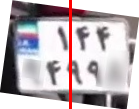


0: 256x416 2 1s, 1 4, 1 5, 1 7, 1 8, 80.1ms
Speed: 1.5ms preprocess, 80.1ms inference, 0.8ms postprocess per image at shape (1, 3, 256, 416)
Rotation angle: -1.5801394989963504

0: 288x416 2 1s, 1 4, 1 5, 1 7, 1 8, 84.2ms
Speed: 1.9ms preprocess, 84.2ms inference, 0.9ms postprocess per image at shape (1, 3, 288, 416)
517-?148?


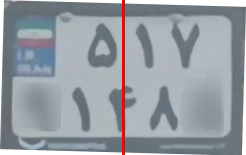


0: 320x416 1 1, 2 4s, 1 5, 2 6s, 1 7, 1 8, 90.3ms
Speed: 1.7ms preprocess, 90.3ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: -11.456471957289065

0: 352x416 1 1, 2 4s, 1 5, 2 6s, 1 7, 1 8, 89.9ms
Speed: 1.6ms preprocess, 89.9ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
147-46658


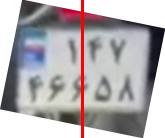


0: 352x416 2 1s, 1 4, 1 5, 1 8, 1 9, 96.6ms
Speed: 1.8ms preprocess, 96.6ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
Rotation angle: -22.143846275429524

0: 384x416 2 1s, 2 4s, 1 5, 1 8, 1 9, 109.6ms
Speed: 1.9ms preprocess, 109.6ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 416)
149-?185?


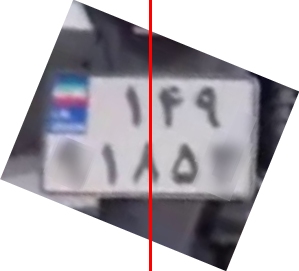


0: 320x416 2 1s, 1 4, 1 5, 2 7s, 1 9, 85.3ms
Speed: 2.0ms preprocess, 85.3ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: 9.690260001948587

0: 352x416 2 1s, 1 4, 1 5, 2 7s, 102.0ms
Speed: 1.9ms preprocess, 102.0ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 416)
147-715??


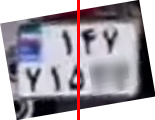


0: 288x416 1 1, 3 4s, 1 8, 3 9s, 91.6ms
Speed: 1.8ms preprocess, 91.6ms inference, 0.8ms postprocess per image at shape (1, 3, 288, 416)
Rotation angle: -1.6182556076375687

0: 320x416 1 1, 3 4s, 1 8, 3 9s, 87.8ms
Speed: 1.7ms preprocess, 87.8ms inference, 1.0ms postprocess per image at shape (1, 3, 320, 416)
144-?4998


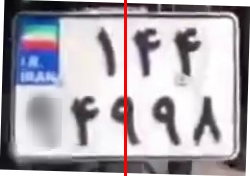


0: 320x416 2 1s, 1 4, 1 5, 2 7s, 1 9, 90.1ms
Speed: 1.7ms preprocess, 90.1ms inference, 1.1ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: 8.467495877486744

0: 352x416 2 1s, 1 4, 1 5, 2 7s, 1 9, 89.8ms
Speed: 1.6ms preprocess, 89.8ms inference, 0.8ms postprocess per image at shape (1, 3, 352, 416)
?47-71519


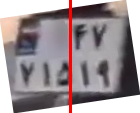


0: 320x416 1 1, 1 3, 1 4, 1 5, 1 6, 2 9s, 86.0ms
Speed: 1.9ms preprocess, 86.0ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: -6.786759465583512

0: 352x416 1 1, 1 3, 1 4, 1 6, 2 9s, 93.0ms
Speed: 1.8ms preprocess, 93.0ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
1??-36499


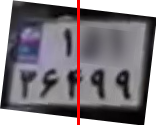


0: 96x416 (no detections), 63.9ms
Speed: 0.9ms preprocess, 63.9ms inference, 0.4ms postprocess per image at shape (1, 3, 96, 416)
Cannot estimate rotation — too few boxes

0: 288x416 3 1s, 1 3, 1 5, 1 6, 81.2ms
Speed: 1.5ms preprocess, 81.2ms inference, 0.9ms postprocess per image at shape (1, 3, 288, 416)
Rotation angle: 4.167839422283046

0: 320x416 3 1s, 1 3, 1 5, 1 6, 85.5ms
Speed: 1.6ms preprocess, 85.5ms inference, 1.1ms postprocess per image at shape (1, 3, 320, 416)
151-??163


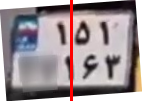


0: 352x416 1 1, 2 4s, 1 5, 1 6, 1 7, 1 8, 1 9, 91.3ms
Speed: 1.8ms preprocess, 91.3ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 416)
Rotation angle: -20.49949127534388

0: 384x416 1 1, 2 4s, 1 5, 1 6, 1 7, 1 8, 1 9, 106.5ms
Speed: 1.9ms preprocess, 106.5ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 416)
146-548?9


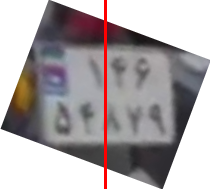


0: 320x416 1 1, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 136.2ms
Speed: 1.6ms preprocess, 136.2ms inference, 1.1ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: -4.765008802842028

0: 320x416 1 1, 2 4s, 1 5, 1 6, 1 7, 1 8, 1 9, 121.7ms
Speed: 2.1ms preprocess, 121.7ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 416)
??6-54879


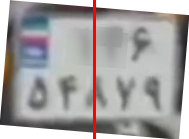


0: 416x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 164.2ms
Speed: 1.9ms preprocess, 164.2ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 416)
Rotation angle: 29.591896748749377

0: 416x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 156.2ms
Speed: 2.5ms preprocess, 156.2ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 416)
146-28386


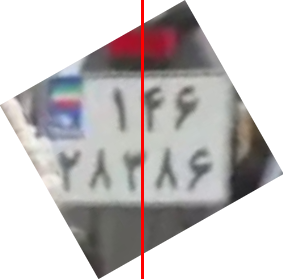


0: 352x416 1 1, 1 3, 1 4, 1 6, 1 8, 152.1ms
Speed: 2.0ms preprocess, 152.1ms inference, 1.2ms postprocess per image at shape (1, 3, 352, 416)
Rotation angle: 23.33840213033979

0: 384x416 1 1, 1 3, 1 4, 1 6, 1 8, 144.3ms
Speed: 1.8ms preprocess, 144.3ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 416)
146-?83??


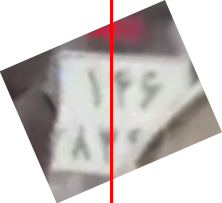


0: 64x416 (no detections), 41.1ms
Speed: 0.6ms preprocess, 41.1ms inference, 0.6ms postprocess per image at shape (1, 3, 64, 416)
Cannot estimate rotation — too few boxes

0: 416x416 2 1s, 2 4s, 2 7s, 1 9, 165.6ms
Speed: 2.4ms preprocess, 165.6ms inference, 1.1ms postprocess per image at shape (1, 3, 416, 416)
Rotation angle: -26.345482834724084

0: 416x416 2 1s, 2 4s, 2 7s, 1 9, 149.6ms
Speed: 2.2ms preprocess, 149.6ms inference, 1.1ms postprocess per image at shape (1, 3, 416, 416)
?47-91174


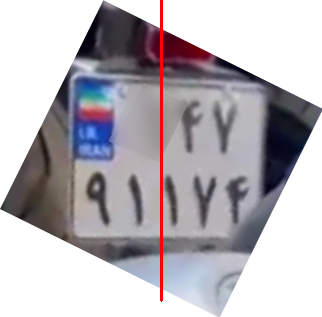


0: 352x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 149.6ms
Speed: 1.9ms preprocess, 149.6ms inference, 1.1ms postprocess per image at shape (1, 3, 352, 416)
Rotation angle: 12.823921884857704

0: 384x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 178.9ms
Speed: 1.9ms preprocess, 178.9ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 416)
146-28386


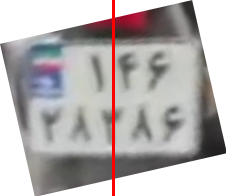


0: 416x352 1 1, 1 2, 1 3, 1 8, 164.6ms
Speed: 1.8ms preprocess, 164.6ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 352)
Rotation angle: 15.28222226856302

0: 416x384 1 1, 1 2, 1 3, 1 8, 173.3ms
Speed: 2.5ms preprocess, 173.3ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 384)
??1-?283?


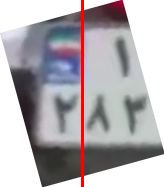


0: 288x416 1 1, 1 4, 1 5, 1 7, 2 8s, 93.2ms
Speed: 1.9ms preprocess, 93.2ms inference, 0.8ms postprocess per image at shape (1, 3, 288, 416)
Rotation angle: -2.899133171228284

0: 288x416 2 1s, 1 4, 1 5, 1 7, 2 8s, 92.7ms
Speed: 1.5ms preprocess, 92.7ms inference, 0.8ms postprocess per image at shape (1, 3, 288, 416)
517-??488


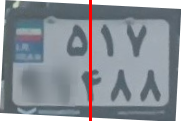


0: 320x416 3 1s, 1 2, 1 4, 1 6, 1 7, 1 9, 91.0ms
Speed: 1.8ms preprocess, 91.0ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: 1.7093516447479815

0: 320x416 3 1s, 1 2, 1 4, 1 6, 1 7, 1 9, 98.4ms
Speed: 1.6ms preprocess, 98.4ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
147-91162


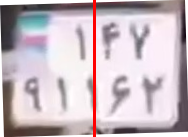


0: 416x416 3 1s, 2 4s, 1 5, 1 7, 1 9, 120.0ms
Speed: 2.3ms preprocess, 120.0ms inference, 1.0ms postprocess per image at shape (1, 3, 416, 416)
Rotation angle: 15.910835083232193

0: 416x416 3 1s, 2 4s, 1 5, 1 7, 1 9, 118.1ms
Speed: 3.2ms preprocess, 118.1ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 416)
147-91154


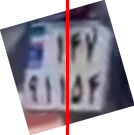


0: 288x416 3 1s, 1 4, 1 7, 1 8, 2 9s, 87.3ms
Speed: 1.4ms preprocess, 87.3ms inference, 0.8ms postprocess per image at shape (1, 3, 288, 416)
Rotation angle: -9.250778320115979

0: 320x416 3 1s, 1 4, 1 7, 1 8, 1 9, 100.9ms
Speed: 1.8ms preprocess, 100.9ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
147-911?8


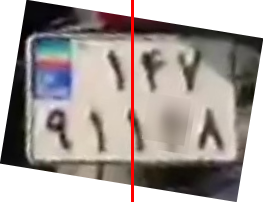


0: 416x416 2 1s, 2 4s, 1 5, 1 7, 111.1ms
Speed: 3.0ms preprocess, 111.1ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 416)
Rotation angle: 18.675616514570365

0: 416x416 2 1s, 2 4s, 1 5, 1 7, 125.1ms
Speed: 2.6ms preprocess, 125.1ms inference, 1.0ms postprocess per image at shape (1, 3, 416, 416)
147-??154


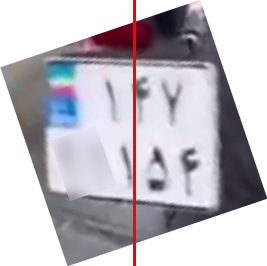


0: 352x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 95.5ms
Speed: 2.0ms preprocess, 95.5ms inference, 0.8ms postprocess per image at shape (1, 3, 352, 416)
Rotation angle: 9.778225651774827

0: 352x416 1 1, 1 2, 1 3, 1 4, 2 6s, 2 8s, 106.0ms
Speed: 1.8ms preprocess, 106.0ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
146-28386


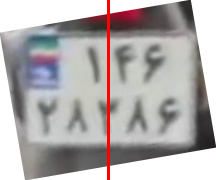


0: 320x416 1 1, 1 2, 1 3, 2 4s, 1 6, 1 8, 1 9, 119.6ms
Speed: 2.0ms preprocess, 119.6ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 416)
Rotation angle: 13.425277615764934

0: 352x416 1 1, 1 2, 1 3, 2 4s, 1 6, 1 8, 1 9, 123.5ms
Speed: 2.5ms preprocess, 123.5ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 416)
146-28394


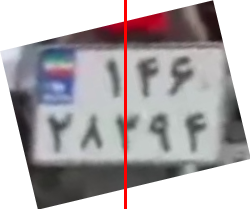


0: 416x384 1 1, 1 2, 1 4, 1 8, 141.6ms
Speed: 2.3ms preprocess, 141.6ms inference, 0.8ms postprocess per image at shape (1, 3, 416, 384)
Rotation angle: 8.76244657462684

0: 416x384 1 1, 1 2, 1 8, 1 9, 126.1ms
Speed: 2.4ms preprocess, 126.1ms inference, 0.8ms postprocess per image at shape (1, 3, 416, 384)
???-?28??


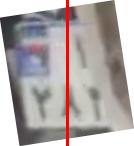

In [18]:
incorrect_samples = []
total = 0
correct = 0
image_folder = 'dataset/motor'

rotated_img = []

img_count = 0

for filename in os.listdir(image_folder):
    if not filename.lower().endswith((".jpg", ".png", ".jpeg")):
            continue

    image_path= os.path.join(image_folder, filename)

    img = cv2.imread(image_path)

    detection = detection_model.predict(img, verbose=False)[0]

    pil_image = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    draw = ImageDraw.Draw(pil_image)

    for box in detection.boxes:
        cls_id = int(box.cls)
        label = detection.names[cls_id]
        xyxy = box.xyxy[0].int().tolist()
        x1, y1, x2, y2 = xyxy

        plate_img = img[y1:y2, x1:x2]

        # Run the pipeline
        pred_text = get_yolo_ocr_result_motor(plate_img, conf_thresh=0.75)
        color =  "red"
        width = 6

        # Draw bounding box and Persian text
        font = ImageFont.truetype(font_path, 50)  # Set font size
        draw.rectangle([x1, y1,x2, y2], outline=color, width=width)
        draw.text((x1, y1 - 30), pred_text, font=font, fill='yellow')

        # Save the annotated image
        output_image_path = f"img_results/image_{img_count:04d}.jpg"  # or .png
        # Save each frame separately
        pil_image.save(output_image_path)
        img_count += 1